In [31]:
import pandas as pd
import folium as fl
import geopandas as geo
import altair as alt
from math import ceil
from shapely import line_merge
from shapely.ops import substring
import matplotlib.pyplot as plt
import contextily as cx
%matplotlib inline

In [32]:
cabecalhos_mapa = {
    "User-Agent": (
        "acidentes-prf-sudeste-2025/1.0 "
        "(+https://github.com/miguel624/acidentes-prf-sudeste-2025)"
    )
}

# Projeto de Análise Exploratória de Dados

##### Autores: Miguel Vitor Pereira; Ricardo Rodrigues Tose; Daniel Furtado Nunes Rocha da Silva
##### Professor: João Lucas Rulff da Costa

## Introdução

Esse trabalho tem como objetivo investigar a relação entre a gravidade dos acidentes com o horário, tipo de acidente, condições da via e do tempo. Buscaremos identificar padrões que orientem as discussões.

Não é necessário nenhum conhecimento prévio sobre o tema. 

## Dados e método

Utilizaremos a base pública da Polícia Rodoviária Federal (PRF), obtida por download do arquivo datatran2025.csv, na versão agrupada por ocorrência. A base nacional consultada contém 72.529 registros e 30 colunas; selecionaremos Minas Gerais, Espírito Santo, Rio de Janeiro e São Paulo no ano de 2025. Para esta análise, consideraremos grave a ocorrência com ao menos um morto ou ferido grave. Verificaremos duplicidades, valores ausentes e categorias antes de calcular contagens e proporções. Sem dados de fluxo de veículos, os resultados descreverão os acidentes registrados, sem estimar o risco por viagem ou estabelecer causalidade.

Observação: Ao pesquisar, foi descoberto que a PRF usa como georreferenciamento o SIRGAS 2000. 

# Preparação do dataset

In [33]:
df = pd.read_csv(r"datatran2025.csv",encoding="latin1",sep=";",decimal=",")
sudeste = df[df["uf"].isin(["SP", "MG", "ES", "RJ"])].copy()
sudeste.isna().sum()
#Existem alguns valores nulos, iremos verificar o que são.

id                         0
data_inversa               0
dia_semana                 0
horario                    0
uf                         0
br                         0
km                         0
municipio                  0
causa_acidente             0
tipo_acidente              0
classificacao_acidente     0
fase_dia                   0
sentido_via                0
condicao_metereologica     0
tipo_pista                 0
tracado_via                0
uso_solo                   0
pessoas                    0
mortos                     0
feridos_leves              0
feridos_graves             0
ilesos                     0
ignorados                  0
feridos                    0
veiculos                   0
latitude                   0
longitude                  0
regional                   0
delegacia                 10
uop                       16
dtype: int64

In [34]:
sudeste[sudeste.isna().any(axis=1)]

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
22094,657145,2025-01-24,sexta-feira,22:05:00,RJ,0,0.0,NITEROI,Frear bruscamente,Colisão traseira,...,0,7,0,0,5,-22.859970,-43.102393,SPRF-RJ,NaN,NaN
28458,666766,2025-02-21,sexta-feira,21:15:00,RJ,0,0.0,RIO DE JANEIRO,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,7,0,0,2,-22.806135,-43.355273,SPRF-RJ,NaN,NaN
30176,669357,2025-03-24,segunda-feira,18:30:00,RJ,0,0.0,RIO DE JANEIRO,Acumulo de areia ou detritos sobre o pavimento,Colisão frontal,...,0,3,0,0,1,-22.808860,-43.341883,SPRF-RJ,NaN,NaN
31329,671127,2025-02-06,quinta-feira,23:00:00,RJ,0,0.0,SAO GONCALO,Pista Escorregadia,Colisão com objeto,...,0,3,0,0,1,-22.787730,-43.007542,SPRF-RJ,NaN,NaN
35906,689128,2025-04-28,segunda-feira,18:05:00,RJ,0,0.0,RIO DE JANEIRO,Ausência de reação do condutor,Colisão transversal,...,0,2,1,0,3,-22.962698,-43.203970,SPRF-RJ,DEL08-RJ,NaN
36475,690004,2025-05-09,sexta-feira,11:25:00,ES,0,0.0,VITORIA,Reação tardia ou ineficiente do condutor,Colisão transversal,...,0,2,0,0,2,-20.309857,-40.314471,SPRF-ES,NaN,NaN
44428,701773,2025-07-01,terça-feira,08:20:00,RJ,0,0.0,RIO DE JANEIRO,Condutor desrespeitou a iluminação vermelha do...,Colisão transversal,...,0,1,2,1,3,-22.985000,-43.191000,SPRF-RJ,DEL01-RJ,NaN
45077,702739,2025-07-05,sábado,16:00:00,RJ,0,0.0,RIO DE JANEIRO,Ausência de reação do condutor,Colisão traseira,...,0,1,0,1,2,-22.980540,-43.365787,SPRF-RJ,NaN,NaN
45200,702907,2025-06-26,quinta-feira,13:45:00,RJ,0,0.0,RIO DE JANEIRO,Frear bruscamente,Colisão traseira,...,0,1,1,1,3,-22.904944,-43.190666,SPRF-RJ,NaN,NaN
45241,702957,2025-07-06,domingo,14:05:00,RJ,0,0.0,RIO DE JANEIRO,Ausência de reação do condutor,Queda de ocupante de veículo,...,0,1,0,1,2,-22.983351,-43.189795,SPRF-RJ,NaN,NaN


Os dados nulos se limitam a quais delegacias e unidade operacional, como todos os outros dados estão completos e essas duas colunas não são de extrema importância, optaremos por deixá-las no dataset e se caso fizermos algum cálculo mais a frente em que esses dados sejam importantes iremos tomar outras medidas de análise.

In [35]:
sudeste["id"].nunique() == sudeste["id"].count()
# Não existe dados de acidentes repetidos.

np.True_

# Como os acidentes registrados se distribuem entre os estados e as rodovias do Sudeste?

## Tratamento de dados.

Decidimos que criar uma camada do mapa contendo as rodovias federais da região ao invés de só plotar os acidentes seria uma abordagem melhor. Enquanto estávamos analisando percebemos que as rodovias federais ficam em poucas regiões do sudeste, e deixar essa representação sem identificar as rodovias iria dificultar imensamente a interpretação do leitor acerca da intensidade dos acidentes em cada região. Por isso, utilizamos o ArcGIS, um sistema de informações geográficas, para coletar os dados das rodovias federais e colocar como uma camada no nosso mapa (esses dados foram feitos no início de 2025, então bate de encontro com o dataset que estamos trabalhando). Ao lidar com os dados do ArcGIS, inicialmente excluímos as rodovias que foram planejadas e iremos analisar também as rovodias em obra de implantação, pois, ao pesquisar a terminologia, essas rodovias podem estar sob um leito natural. Então para saber se ela é ou não passível de análise no nosso dataset iremos comparar ao plotá-los. OBSERVAÇÃO: Percebemos que havia apenas uma rodovia em estado de obra de implantação, portanto optamos por deixá-la inclusa na construção da camada das rodovias.

In [36]:
dados_mapa = sudeste.copy()

acidentes_geo = geo.GeoDataFrame(
    dados_mapa,
    geometry=geo.points_from_xy(
        dados_mapa["longitude"],
        dados_mapa["latitude"]
    ),
    crs="EPSG:4674"
)

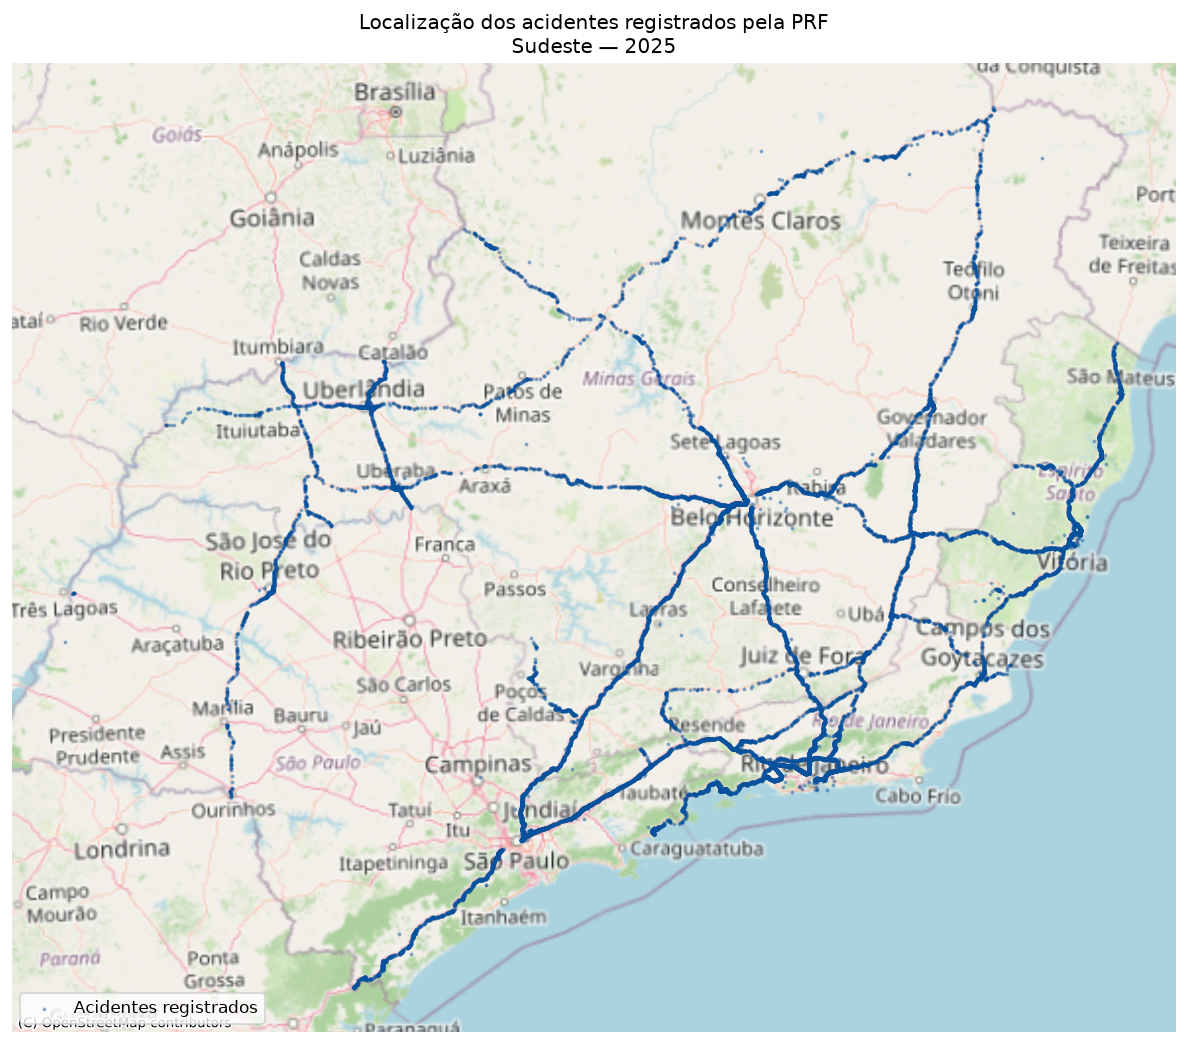

In [37]:
acidentes_figura = acidentes_geo.to_crs("EPSG:31983")

fig, ax = plt.subplots(figsize=(10, 9), dpi=120)

acidentes_figura.plot(
    ax=ax,
    color="#08519c",
    markersize=2,
    alpha=0.35,
    zorder=2,
    label="Acidentes registrados"
)

cx.add_basemap(
    ax,
    source=cx.providers.OpenStreetMap.Mapnik,
    headers=cabecalhos_mapa,
    crs=acidentes_figura.crs,
    zoom=6,
    zorder=0
)

ax.set_title(
    "Localização dos acidentes registrados pela PRF\n"
    "Sudeste — 2025"
)

ax.set_axis_off()
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

In [38]:
import requests

consulta = (
    "https://geo.infrasa.gov.br/server/rest/services/"
    "Hosted/Rodovias_Federais/FeatureServer/0/query"
)

parametros = {
    "where": "sg_uf IN ('MG', 'ES', 'RJ', 'SP')",
    "outFields": "*",
    "returnGeometry": "true",
    "outSR": 4326,
    "resultRecordCount": 20000,
    "f": "geojson"
}

resposta = requests.get(
    consulta,
    params=parametros,
    timeout=60
)

resposta.raise_for_status()
conteudo = resposta.json()

if "error" in conteudo:
    raise RuntimeError(conteudo["error"])

malha = geo.GeoDataFrame.from_features(
    conteudo["features"],
    crs="EPSG:4326"
)

In [39]:
malha_analise = malha[
    (malha["ds_jurisdi"] == "Federal")
    & ~malha["ds_legenda"].isin([
        "Planejada"
    ])
].copy()

In [40]:
malha_analise = malha_analise.rename(columns={
    "fid": "id_trecho",
    "sg_uf": "uf",
    "vl_br": "br",
    "vl_km_inic": "km_inicial",
    "vl_km_fina": "km_final",
    "vl_extensa": "extensao_km"
})

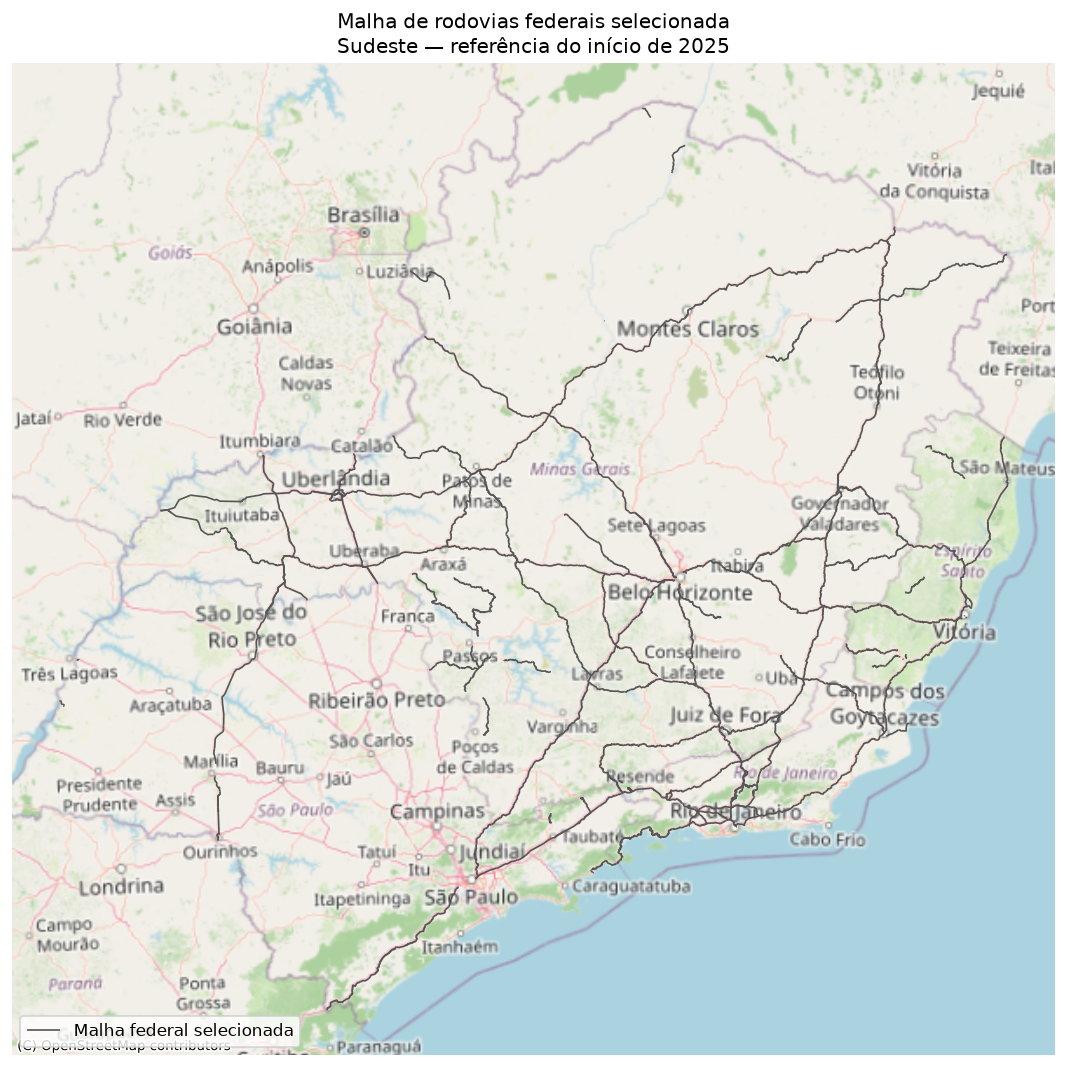

In [41]:
malha_figura = malha_analise.to_crs("EPSG:31983")

fig, ax = plt.subplots(figsize=(10, 9), dpi=120)

malha_figura.plot(
    ax=ax,
    color="#555555",
    linewidth=1,
    zorder=2,
    label="Malha federal selecionada"
)

cx.add_basemap(
    ax,
    source=cx.providers.OpenStreetMap.Mapnik,
    headers=cabecalhos_mapa,
    crs=malha_figura.crs,
    zoom=6,
    zorder=0
)

ax.set_title(
    "Malha de rodovias federais selecionada\n"
    "Sudeste — referência do início de 2025"
)

ax.set_axis_off()
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

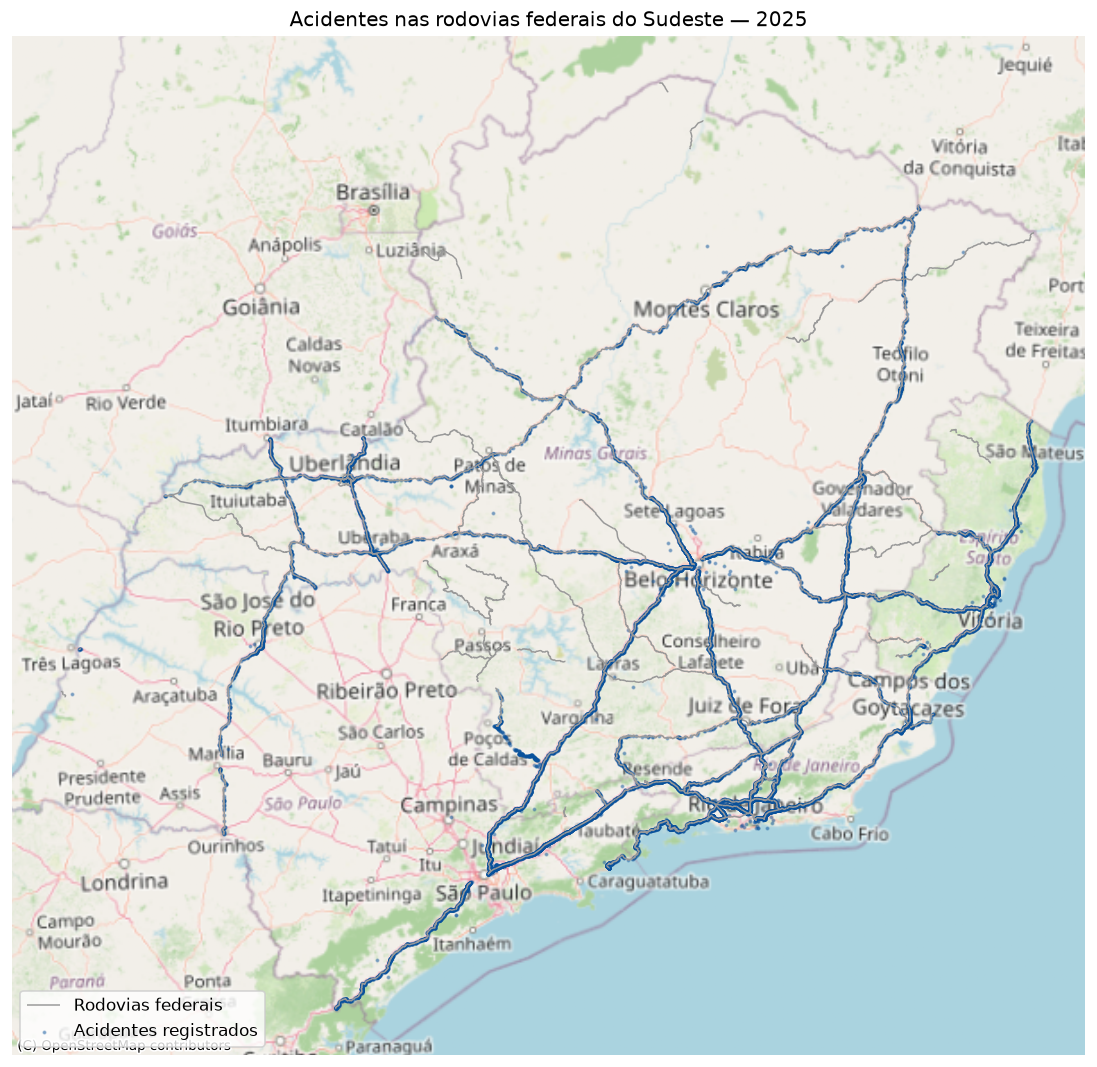

In [42]:
crs_figura = "EPSG:31983"

malha_figura = malha_analise.to_crs(crs_figura)
acidentes_figura = acidentes_geo.to_crs(crs_figura)

fig, ax = plt.subplots(
    figsize=(10, 9),
    dpi=120
)

malha_figura.plot(
    ax=ax,
    color="#999999",
    linewidth=0.9,
    label="Rodovias federais"
)

acidentes_figura.plot(
    ax=ax,
    color="#08519c",
    markersize=2,
    alpha=0.35,
    label="Acidentes registrados"
)

cx.add_basemap(
    ax,
    source=cx.providers.OpenStreetMap.Mapnik,
    headers=cabecalhos_mapa,
    crs=malha_figura.crs,
    zoom=6,
    zorder=0
)

ax.set_title(
    "Acidentes nas rodovias federais do Sudeste — 2025"
)

ax.set_axis_off()
ax.legend(loc="lower left")

plt.tight_layout()
plt.show()

No mapa acima percebemos que existe alguns poucos casos em que os acidentes não estão acima de uma rodovia federal, mas a grande maioria esmagadora está de acordo com o mapa das rodovias que fizemos. A partir de agora, para fazermos nosso geográfico evidenciando a distribuição de acidentes na região sudeste, iremos fazer com que cada acidente esteja designado a uma parte da rodovia, para que dessa forma possamos calcular a concentração de acidentes em uma determinada distância por rodovia (iremos usar 10km como base). Apenas reforçando, optamos por fazer dessa maneira ao invés de apenas fazer um mapa de calor pois seria impossível o leitor saber que os acidentes não estão distribuídos em todas as rodovias federais do país.

O nosso critério para a associação dos acidentes com uma parte da rodovia foi: Ele será associada ao local que se encontra com a menor distância, e tem que estar a um limite de 200 metros da estrada para ser associado.(Esse limite imposto foi uma abordagem baseada em palpites, não houve uma pesquisa a fundo sobre isso)

In [43]:
malha_base = malha_analise[
    ["uf", "br", "geometry"]
].copy()

acidentes_base = acidentes_geo[
    ["id", "uf", "br", "km", "municipio", "geometry"]
].copy()

for tabela in [malha_base, acidentes_base]:
    tabela["br"] = (
        tabela["br"]
        .astype(int)
        .astype(str)
        .str.zfill(3)
    )

#Pegamos apenas as colunas necessária e padronizamos os números da BR das tabelas.